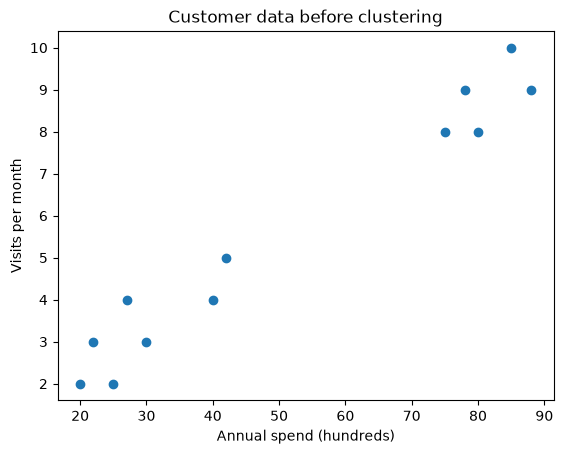

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


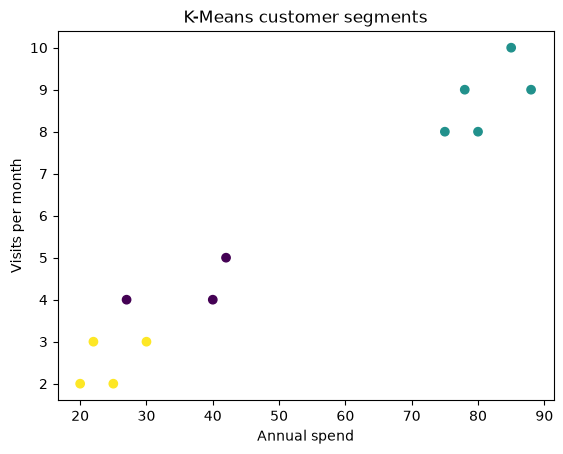

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        2
1            22               3        2
2            25               2        2
3            27               4        0
4            30               3        2
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0
2 inertia: 2.03 silhouette: 0.786
3 inertia: 0.97 silhouette: 0.591
4 inertia: 0.66 silhouette: 0.449
5 inertia: 0.38 silhouette: 0.4
Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

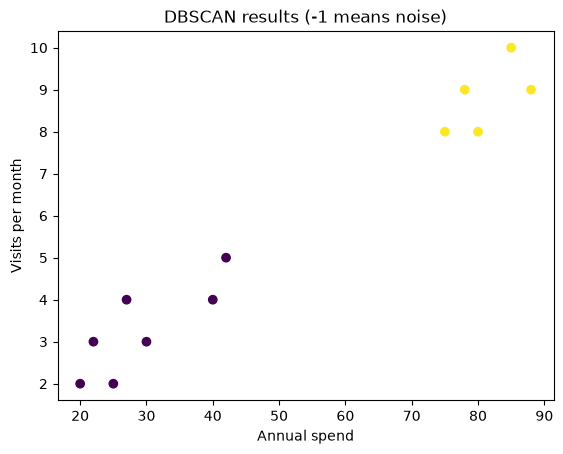

Explained variance: [0.73  0.229]


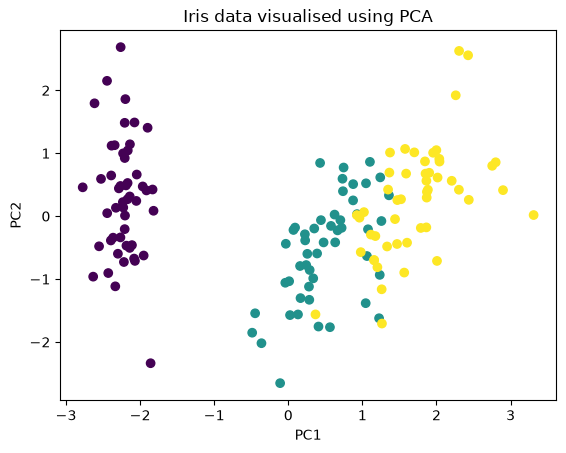

[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
customers = pd.DataFrame({
    "AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()
print(customers)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))
    from sklearn.cluster import DBSCAN
db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)
print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)
print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()
from sklearn.ensemble import IsolationForest
import numpy as np
transactions = np.array([
[20, 2], [22, 3], [18, 2], [25, 3],
[21, 2], [23, 4], [19, 3], [250, 20]
])
detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)
for row, label in zip(transactions, labels):
  print(row, "Anomaly" if label == -1 else "Normal")

Libraries Imported Successfully!

Customer Dataset:
    Customer_ID  Annual_Spending  Visits_Per_Month
0             1            10000                 1
1             2            12000                 2
2             3            15000                 2
3             4            18000                 3
4             5            20000                 3
5             6            40000                 5
6             7            45000                 6
7             8            48000                 6
8             9            52000                 7
9            10            55000                 8
10           11            80000                10
11           12            85000                11
12           13            90000                12
13           14            95000                13
14           15           100000                14

Features Scaled Successfully!

K-Means Clustering Result:
    Customer_ID  Annual_Spending  Visits_Per_Month  Cluster
0            

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


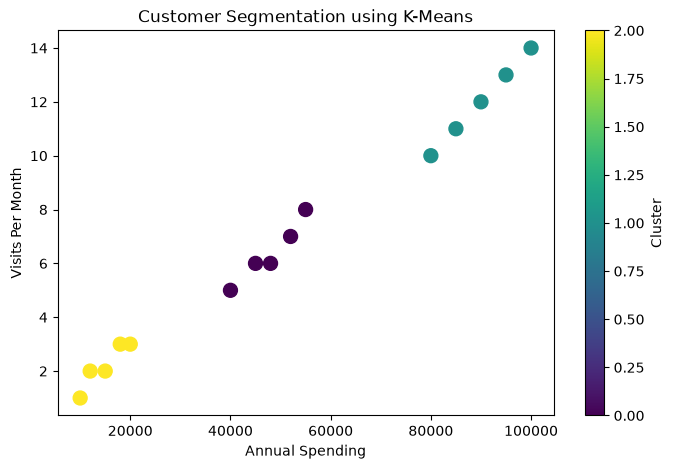


Average Spending of Each Cluster:
Cluster
0    48000.0
1    90000.0
2    15000.0
Name: Annual_Spending, dtype: float64

K-Means Model Comparison:
K = 2
Inertia (Elbow): 6.855
Silhouette Score: 0.648

K = 3
Inertia (Elbow): 1.508
Silhouette Score: 0.719

K = 4
Inertia (Elbow): 0.883
Silhouette Score: 0.64



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

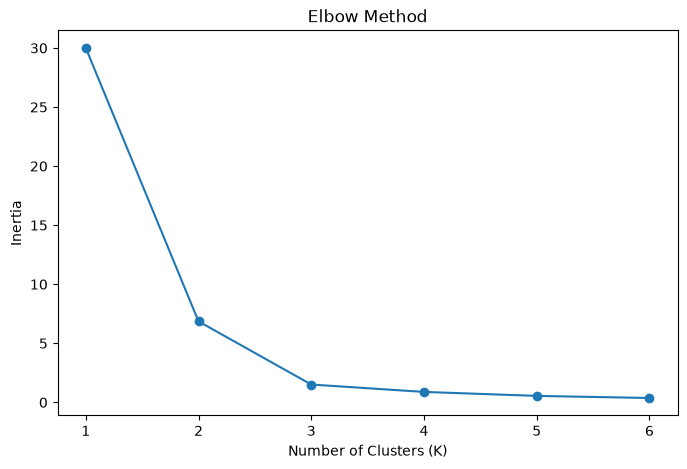

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


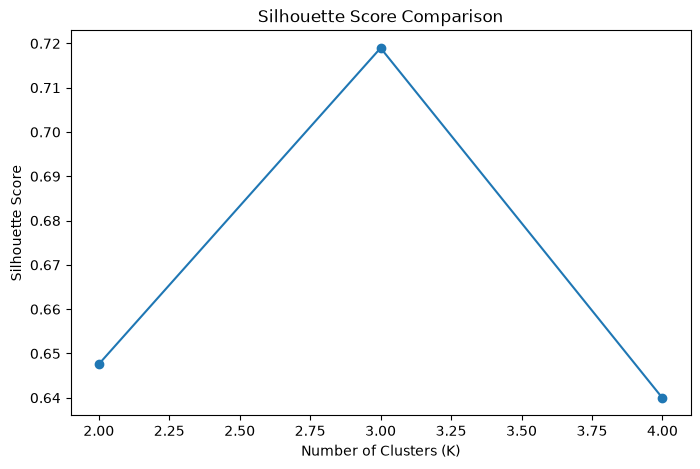


DBSCAN Clustering Result:
    Customer_ID  Annual_Spending  Visits_Per_Month  Cluster  DBSCAN_Cluster
0             1            10000                 1        2               0
1             2            12000                 2        2               0
2             3            15000                 2        2               0
3             4            18000                 3        2               0
4             5            20000                 3        2               0
5             6            40000                 5        0               1
6             7            45000                 6        0               1
7             8            48000                 6        0               1
8             9            52000                 7        0               1
9            10            55000                 8        0               1
10           11            80000                10        1               2
11           12            85000                11        1  

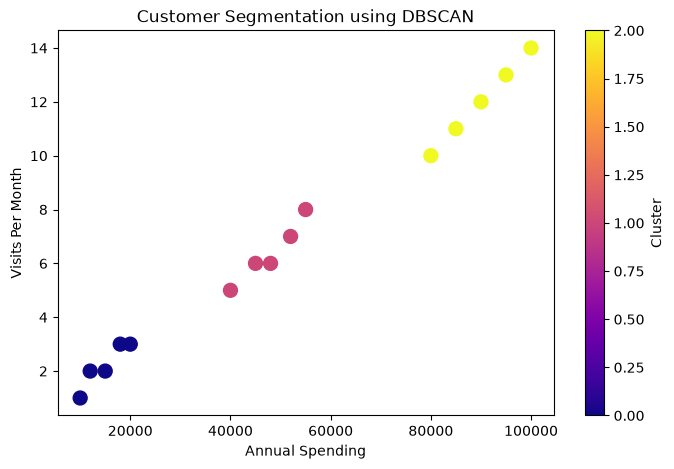


FINAL CUSTOMER SEGMENTATION
    Customer_ID  Annual_Spending  Visits_Per_Month  Cluster  DBSCAN_Cluster
0             1            10000                 1        2               0
1             2            12000                 2        2               0
2             3            15000                 2        2               0
3             4            18000                 3        2               0
4             5            20000                 3        2               0
5             6            40000                 5        0               1
6             7            45000                 6        0               1
7             8            48000                 6        0               1
8             9            52000                 7        0               1
9            10            55000                 8        0               1
10           11            80000                10        1               2
11           12            85000                11        1

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
print("Libraries Imported Successfully!")
data = {
    "Customer_ID": range(1, 16),
    "Annual_Spending": [
        10000, 12000, 15000, 18000, 20000,
        40000, 45000, 48000, 52000, 55000,
        80000, 85000, 90000, 95000, 100000
    ],
    "Visits_Per_Month": [
        1, 2, 2, 3, 3,
        5, 6, 6, 7, 8,
        10, 11, 12, 13, 14
   ]
}
df = pd.DataFrame(data)
print("\nCustomer Dataset:")
print(df)
X = df[["Annual_Spending", "Visits_Per_Month"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("\nFeatures Scaled Successfully!")
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print("\nK-Means Clustering Result:")
print(df)
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Annual_Spending"],
    df["Visits_Per_Month"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)
plt.xlabel("Annual Spending")
plt.ylabel("Visits Per Month")
plt.title("Customer Segmentation using K-Means")
plt.colorbar(label="Cluster")
plt.show()
average_spending = df.groupby("Cluster")["Annual_Spending"].mean()
print("\nAverage Spending of Each Cluster:")
print(average_spending)
# 8. COMPARE K=2, K=3 AND K=4
print("\nK-Means Model Comparison:")
for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print("K =", k)
    print("Inertia (Elbow):", round(model.inertia_, 3))
    print("Silhouette Score:", round(score, 3))
    print()
inertia_values = []
for k in range(1, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(range(1, 7), inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()
k_values = [2, 3, 4]
silhouette_values = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.show()
dbscan = DBSCAN(eps=0.65, min_samples=3)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)
print("\nDBSCAN Clustering Result:")
print(df)
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Annual_Spending"],
    df["Visits_Per_Month"],
    c=df["DBSCAN_Cluster"],
    cmap="plasma",
    s=100
)
plt.xlabel("Annual Spending")
plt.ylabel("Visits Per Month")
plt.title("Customer Segmentation using DBSCAN")
plt.colorbar(label="Cluster")
plt.show()
print("\nFINAL CUSTOMER SEGMENTATION")
print(df)
print("\nPractical 2 Completed Successfully!")